# L2/3 pyramidal neuron

Builds the model L2/3 pyramidal cell and reproduces every manuscript figure
depicting its dynamics.

Figures are written to `results/single_cell_sim/l23/`.

Note: action potential measures quantified with `h.dt=0.01`,
all other simulations run with NEURON/HNN default `h.dt=0.025`.

| Manuscript figure | Section |
| --- | --- |
| Supp. Fig. 1e–f | Non-uniform conductance distributions |
| Fig. 4 | Somatic dynamics vs. Allen data |
| Fig. 5 | Calcium spikes |
| Supp. Fig. 2d–e | Signal attenuation |
| Supp. Fig. 2g | Single-cell dipolar currents |

In [1]:
# Author: Katharina Duecker <katharina.duecker@gmail.com>
# last checked: 18-Oct-2026

In [2]:
# imports
import os

import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
import matplotlib.gridspec as gridspec
import numpy as np
from scipy import signal
from scipy.signal import find_peaks
from scipy.optimize import curve_fit

# hnn_tuning utils
from hnn_tuning import results_dir, ALLEN_DATA
from hnn_tuning.l23_plot_utils import get_l2pyr, get_colormap_l23
from hnn_tuning.plot_utils import add_scalebar, get_cmap_neurons
from hnn_tuning.pyramidal_sim_utils import (
    attenuation_from_section,
    exp_decay,
    stim_dpl,
    plot_dpl,
)
from hnn_tuning.model_data_comparison import exp_func, load_ephys_csv

from hnn_core import duecker_ET_model
from hnn_tuning._paths import EPSP_MOD

# NEURON simulation settings
import neuron
# directory holding the custom epsp.mod point process
neuron.load_mechanisms(str(EPSP_MOD))
from neuron import h
h.load_file('stdrun.hoc')
from neuron.units import ms

# plotting settings
plt.rcParams['svg.fonttype'] = 'none'
plt.rcParams['pdf.fonttype'] = '42'
# global font sizes
plt.rcParams['font.size'] = 10
plt.rcParams['axes.titlesize'] = 10
plt.rcParams['axes.labelsize'] = 10
plt.rcParams['xtick.labelsize'] = 10
plt.rcParams['ytick.labelsize'] = 10
plt.rcParams['legend.fontsize'] = 10

pth_data = str(ALLEN_DATA / 'l23')
figpth = results_dir('single_cell_sim', 'l23')
os.makedirs(figpth, exist_ok=True)

# palettes
_, cols_dist, _, _ = get_colormap_l23()          # attenuation (distance colouring)
cm_neurons = get_cmap_neurons()              # per-cell-type line colours

plt.close('all')


-------------------------------------------------------------------------------------------------------
Thank you for installing HNN-Core! Please fill out our survey at:

    https://docs.google.com/forms/d/e/1FAIpQLSfN2F4IkGATs6cy1QBO78C6QJqvm9y14TqsCUsuR4Rrkmr1Mg/viewform

Filling out our survey REALLY helps us to provide support and maintenance for HNN-Core.

This message should only display once, after you have first installed HNN-Core. Happy modeling!
-------------------------------------------------------------------------------------------------------

Mechanisms already loaded from path: /Users/katharinaduecker/Documents/projects_brown/hnn-tuning/single_cell_sim.  Aborting.


## Supp. Fig. 1e–f — non-uniform conductance distributions

Apical `gbar` for Ih, Ca_HVA, Ca_LVA and SK-E2 as a function of distance from
the soma.

Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.


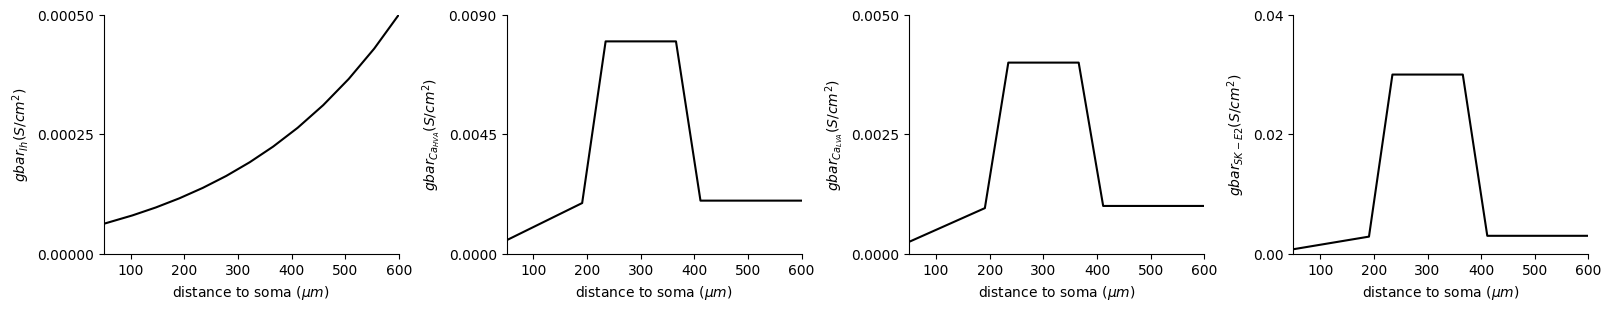

In [3]:
l2pyr = get_l2pyr()

# collect conductances gbar at each distance
distance_apical = []
gbar_Ih_apical = []
gbar_Ca_HVA_apical = []
gbar_Ca_LVA_apical = []
gbar_SK_E2_apical = []

apical_sections = ['apical_trunk', 'apical_1', 'apical_tuft']         # apical compartments only
h.distance(sec=l2pyr._nrn_sections['soma'])
for section in apical_sections:
    for seg in l2pyr._nrn_sections[section]:
        distance_apical.append(h.distance(seg.x, sec=seg.sec))
        gbar_Ih_apical.append(seg.gbar_Ih_hay2011)
        gbar_Ca_HVA_apical.append(seg.gbar_Ca_HVA_hay2011)
        gbar_Ca_LVA_apical.append(seg.gbar_Ca_LVAst_hay2011)
        gbar_SK_E2_apical.append(seg.gbar_SK_E2_hay2011)

fig, ax = plt.subplots(1, 4, figsize=(16, 3), constrained_layout=True)
ax = ax.flatten()
ax[0].plot(distance_apical, gbar_Ih_apical, color='k')
ax[0].set_ylabel(r'$gbar_{Ih} (S/cm^2)$')
ax[0].set_ylim([0, 0.0005])
ax[0].set_yticks(np.arange(0, 0.00051, 0.00025))
ax[1].plot(distance_apical, gbar_Ca_HVA_apical, color='k')
ax[1].set_ylabel(r'$gbar_{Ca_{HVA}} (S/cm^2)$')
ax[1].set_ylim([0, 0.009])
ax[1].set_yticks(np.linspace(0, 0.009, 3))
ax[2].plot(distance_apical, gbar_Ca_LVA_apical, color='k')
ax[2].set_ylabel(r'$gbar_{Ca_{LVA}} (S/cm^2)$')
ax[2].set_ylim([0, 0.005])
ax[2].set_yticks(np.arange(0, 0.0051, 0.0025))
ax[3].plot(distance_apical, gbar_SK_E2_apical, color='k')
ax[3].set_ylabel(r'$gbar_{SK-E2} (S/cm^2)$')
ax[3].set_ylim([0, 0.04])
ax[3].set_yticks([0, 0.02, 0.04])
ax[3].set_xlabel(r'distance to soma ($\mu m$)')
ax[2].set_xlabel(r'distance to soma ($\mu m$)')
ax[1].set_xlabel(r'distance to soma ($\mu m$)')
ax[0].set_xlabel(r'distance to soma ($\mu m$)')

for a in ax:
    a.set_xlim([50, 600])
    a.spines['top'].set_visible(False)
    a.spines['right'].set_visible(False)
fig.savefig(figpth / 'l23_conductances_inp_res_membrane_time.pdf')
fig.savefig(figpth / 'l23_conductances_inp_res_membrane_time.svg')

## Plotting functions

In [4]:
def _despine(ax):
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)


def plot_rmp(ax):
    ax.plot(rmp_t, rmp_v, color=cm_neurons[1], linewidth=1.5)
    ax.plot(rmp_t[-3], rmp_v[-3], 'o', color='k', markersize=7)
    ax.set_ylabel('membrane potential (mV)')
    ax.set_xlabel('time (ms)')
    ax.set_ylim([-75, -65])
    ax.set_yticks([-75, -65])
    _despine(ax)


def plot_action_potential(ax):
    ax.plot(ap_t, ap_v, color=cm_neurons[1], linewidth=1.5)
    ax.set_ylabel('membrane potential (mV)')
    ax.set_xlabel('time (ms)')
    ax.set_ylim([-75, 50])
    ax.set_yticks([-70, 0, 50])
    ax.set_xlim([0, 20])
    ax.set_xticks([0, 10, 20])
    _despine(ax)


def plot_isi(ax):
    ax.plot(isi_t, isi_v, color=cm_neurons[1], linewidth=1.5)
    ax.set_xlim([0, 1000])
    ax.set_ylim([-75, 50])
    ax.set_yticks([-70, 0, 50])
    ax.set_xlabel('time (ms)')
    _despine(ax)


def plot_fr_slope(ax):
    ax.plot(fr_ampl, fr_vals, color=cm_neurons[1], linewidth=1.5)
    ax.set_yticks([0, 40, 80])
    ax.set_ylabel('FR (Hz)')
    ax.set_xlabel('amplitude (nA)')
    ax.set_xticks([0.1, 0.3, 0.5, 0.7])
    ax.set_xlim([0.1, 0.7])
    ax.set_ylim([-1, 80])
    _despine(ax)


def plot_hyperpol(ax):
    for t_np, v_np in sag_traces:
        ax.plot(t_np, v_np, color=cm_neurons[1], linewidth=1.5)
    ax.set_xlim([0, 700])
    ax.set_ylabel('membrane potential (mV)')
    ax.set_xlabel('time (ms)')
    ax.set_yticks([-130, -110, -90, -70])
    ax.set_ylim([-130, -70])
    _despine(ax)


def plot_all_experiments(fig=None):
    """Assemble every panel into the original combined.
    """
    if fig is None:
        fig = plt.figure(figsize=(8, 4), constrained_layout=True)
    gs = GridSpec(2, 3, figure=fig, width_ratios=[0.5, 0.5, 1.4])
    axes = [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1]),
            fig.add_subplot(gs[0, 2]), fig.add_subplot(gs[1, :2]),
            fig.add_subplot(gs[1, 2])]
    plot_rmp(axes[0])
    plot_action_potential(axes[1])
    plot_isi(axes[2])
    plot_fr_slope(axes[3])
    plot_hyperpol(axes[4])
    return fig, axes

## Fig. 4 — somatic dynamics vs. Allen Cell Types data

Model electrophysiological features measured against human Allen Cell Types
recordings for layers 2 and 3. Allen data were extracted by
`extract_ephys/allen_get_ephys_data.py` and stored in `data/allen-data/l23`.
Manuscript figure is created by combining all subpanels using `plot_all_experiments`.

In [5]:
# Load Allen reference data (layers 2 and 3)
l2_allen = load_ephys_csv(os.path.join(pth_data, 'ephys_l2.csv'))
l3_allen = load_ephys_csv(os.path.join(pth_data, 'ephys_l3.csv'))

ephys_measures = dict()

### Resting membrane potential (RMP)

Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
{'soma': np.float64(-73.39101049198933), 'basal_1': np.float64(-73.39624049527613), 'basal_2': np.float64(-73.41158184233909), 'basal_3': np.float64(-73.41158184233909), 'apical_oblique': np.float64(-73.35837198815267), 'apical_trunk': np.float64(-73.36674756100443), 'apical_1': np.float64(-73.19824973860908), 'apical_tuft': np.float64(-72.97653774955523)}


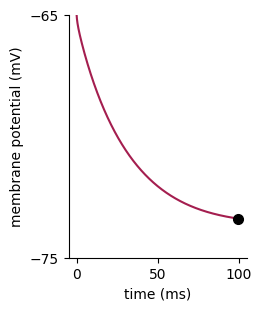

In [6]:
l2pyr = get_l2pyr()

section_names = ['soma', 'basal_1', 'basal_2', 'basal_3', 'apical_oblique', 'apical_trunk', 'apical_1', 'apical_tuft']
v_s = []
for s, section in enumerate(section_names):
    v_s.append(h.Vector().record(l2pyr._nrn_sections[section](0.5)._ref_v))

t = h.Vector().record(h._ref_t)
h.celsius = 37
h.finitialize(-65)
h.continuerun(100 * ms)
h.dt = 0.025

v_init = {}
for s, section in enumerate(section_names):
    if section == 'soma':
        soma_voltg = v_s[s].as_numpy()

    v = v_s[s].as_numpy()
    v_init[section] = v[-1]

print(v_init, flush=True)

ephys_measures['RMP'] = v_init['soma']

# store results for plotting
rmp_t = t.as_numpy().copy()
rmp_v = soma_voltg.copy()

fig, ax = plt.subplots(figsize=(2.5, 3), constrained_layout=True)
plot_rmp(ax)
plt.show()

### Action potential

Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.


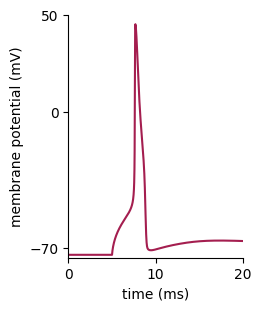

In [7]:
l2pyr = get_l2pyr()

stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 5
stim.dur = 3
stim.amp = 1.5
clamp_current = h.Vector().record(stim._ref_i)

t = h.Vector().record(h._ref_t)
v_soma = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.dt = 0.01
h.finitialize()
h.continuerun(20 * ms)

ap, properties = find_peaks(v_soma.as_numpy(), height=0, width=0)

v_np = v_soma.as_numpy()
t_np = t.as_numpy()
smooth_v = signal.savgol_filter(np.diff(v_np), 201, 3, mode='constant')

ap_thresh_idx = np.where(smooth_v / np.diff(t_np)[0] > 20)[0][0] + 1

ap_thresh = v_np[ap_thresh_idx]

if len(ap) > 0:
    ap_peak = properties['peak_heights'][0]
else:
    ap_peak = v_soma[-1]

start_ap = int(ap[0])
stop_ap = np.argmin(np.abs(t_np - (t_np[ap[0]] + 5)))
elbow_p = int(np.argmin(v_np[start_ap:stop_ap]) + start_ap)

upstroke = np.mean(np.gradient(v_np[ap_thresh_idx:int(ap[0])]))
downstroke = np.mean(np.gradient(v_np[int(ap[0]):elbow_p]))

ap_up_down = np.abs(upstroke / downstroke)

ap_width = properties['widths'][0] * h.dt
ephys_measures['ap_width'] = ap_width
ephys_measures['upstroke_downstroke'] = ap_up_down
ephys_measures['ap_threshold'] = v_soma[ap_thresh_idx]

# store results for plotting
ap_t = t.as_numpy().copy()
ap_v = v_soma.as_numpy().copy()
ap_elbow_p = elbow_p

fig, ax = plt.subplots(figsize=(2.5, 3), constrained_layout=True)
plot_action_potential(ax)
plt.show()

### Inter-spike interval (ISI)

Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.


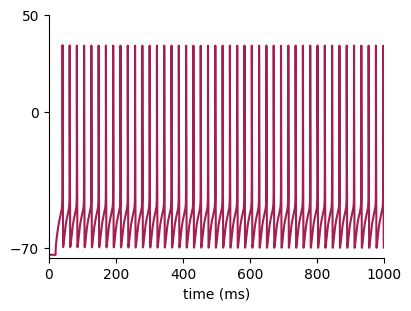

In [8]:
amp_isi = np.mean(np.concatenate((l2_allen['max_amp_isi'].dropna().values, l3_allen['max_amp_isi'].dropna().values))) * 1.2
l2pyr = get_l2pyr()
stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 20
stim.dur = 1000
stim.amp = amp_isi

t = h.Vector().record(h._ref_t)
soma_v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

h.celsius = 37
h.finitialize()
h.continuerun(1020 * ms)

aps = find_peaks(soma_v, height=0)[0]
ephys_measures['first_isi'] = np.diff(t.as_numpy()[aps])[0]
ephys_measures['mean_isi'] = np.mean(np.diff(t.as_numpy()[aps]))

# store results for plotting
isi_t = t.as_numpy().copy()
isi_v = soma_v.as_numpy().copy()

fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
plot_isi(ax)
plt.show()

### Firing-rate slope (FI curve)

Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.


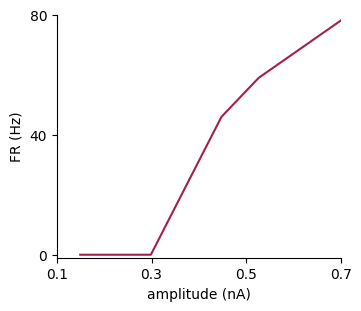

In [9]:
l_stim = 1000

max_amp_isi = np.max(np.concatenate((l2_allen['max_amp_isi'].dropna().values, l3_allen['max_amp_isi'].dropna().values)))

ampl = np.array([amp_isi / 3, amp_isi / 1.5, amp_isi, max_amp_isi / 1.5, max_amp_isi])

soma_v = np.zeros((len(ampl), int(1 / h.dt * l_stim + 1)))
fr = np.zeros_like(ampl)

for i, amp in enumerate(ampl):

    l2pyr = get_l2pyr()

    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 20
    stim.dur = 1000
    stim.amp = amp
    clamp_current = h.Vector().record(stim._ref_i)

    t = h.Vector().record(h._ref_t)
    v_soma = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    h.celsius = 37
    h.finitialize()
    h.continuerun((l_stim + stim.delay) * ms)

    pk = find_peaks(v_soma, height=0)

    fr[i] = len(pk[0])

pA = 0.001  # nA (convert nA to pA)
ephys_measures['FR_slope'] = np.polyfit(ampl, fr, 1)[0]
ephys_measures['FR_slope'] *= pA

# store results for plotting
fr_ampl = ampl.copy()
fr_vals = fr.copy()

fig, ax = plt.subplots(figsize=(3.5, 3), constrained_layout=True)
plot_fr_slope(ax)
plt.show()

### Hyperpolarization (sag ratio and membrane time constant)

Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn_tuning/model_data_comparison.py:15: RuntimeWarning: overflow encountered in exp
  return A * (1 - np.exp(-t / tau)) + C


Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.


/Users/katharinaduecker/Documents/projects_brown/hnn-tuning/hnn_tuning/model_data_comparison.py:15: RuntimeWarning: overflow encountered in multiply
  return A * (1 - np.exp(-t / tau)) + C


Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.


/var/folders/7z/wfcp96210zb700801j0vcbmw0000gn/T/ipykernel_19913/3142105889.py:54: OptimizeWarning: Covariance of the parameters could not be estimated
  popt, pcov = curve_fit(exp_func, t_rise, v_rise, p0=[2, abs(delta_v), v_rise[0]])


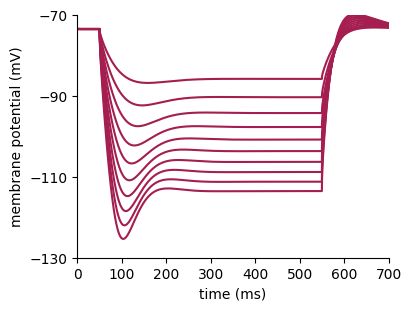

In [10]:
sag_stim_amp_l2 = l2_allen['sag_stim_amp'].dropna()
sag_stim_amp_l2 = np.concatenate(sag_stim_amp_l2.values)

sag_stim_amp_l3 = l3_allen['sag_stim_amp'].dropna()
sag_stim_amp_l3 = np.concatenate(sag_stim_amp_l3.values)

sag_stim_amp = np.linspace(-0.5, -0.1, 10)  # np.unique(np.concatenate((sag_stim_amp_l2, sag_stim_amp_l3)))
tau_ms = np.zeros_like(sag_stim_amp)
steady_state = np.zeros_like(sag_stim_amp)
min_membr_pot = np.zeros_like(sag_stim_amp)
v_bsl = np.zeros_like(sag_stim_amp)
sag_traces = []
for i, amp in enumerate(sag_stim_amp):
    l2pyr = get_l2pyr()

    h.distance(sec=l2pyr._nrn_sections['soma'])

    stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
    stim.delay = 50
    stim.dur = 500
    stim.amp = amp

    v = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)

    t = h.Vector().record(h._ref_t)

    h.celsius = 37
    h.finitialize()
    h.continuerun(700 * ms)

    v_np = v.as_numpy()
    t_np = t.as_numpy()

    # Sag ratio
    steady_idx = np.argmin(np.abs(t - ((stim.delay + stim.dur) * 0.9)))
    steady_state[i] = v_np[steady_idx]
    start_peak = np.argmin(np.abs(t_np - (t_np[np.argmin(v_np)] - 5 / 2)))  # from Allen ipfx https://github.com/AllenInstitute/ipfx/blob/c607a36e25618a6bb8ba5438c1cd945fb429e659/ipfx/subthresh_features.py#L131
    end_peak = np.argmin(np.abs(t_np - (t_np[np.argmin(v_np)] + 5 / 2)))
    min_membr_pot[i] = v_np[start_peak:end_peak].mean()
    bsl_end = np.argmin(np.abs(t - stim.delay))
    bsl_start = np.argmin(np.abs(t - (stim.delay - 10)))

    v_bsl[i] = np.mean(v_np[bsl_start:bsl_end])
    # Membrane time constant

    start_idx = np.where(t_np > stim.delay)[0][0]
    end_idx = np.where(t_np > stim.delay + stim.dur * 0.9)[0][0]      # steady state, see https://pmc.ncbi.nlm.nih.gov/articles/PMC2775376/

    t_rise = t_np[start_idx:end_idx] - stim.delay  # Time starting at 0
    v_rise = v_np[start_idx:end_idx]

    delta_v = np.mean(v_rise) - np.mean(v_np[:start_idx])
    # Fit the exponential function to the data
    popt, pcov = curve_fit(exp_func, t_rise, v_rise, p0=[2, abs(delta_v), v_rise[0]])
    tau_ms[i] = popt[0]  # This is the fitted time constant in ms

    # store this trace for plotting (copy: the hoc Vectors are reused each loop)
    sag_traces.append((t_np.copy(), v_np.copy()))

avg_tau_ms = np.mean(tau_ms)

ephys_measures['tau'] = avg_tau_ms
ephys_measures['sag'] = np.mean((min_membr_pot - steady_state) / (min_membr_pot - v_bsl))

fig, ax = plt.subplots(figsize=(4, 3), constrained_layout=True)
plot_hyperpol(ax)
plt.show()

### Combined figure (original layout)

Reassembles all five somatic-dynamics panels into the original 2x3 layout.

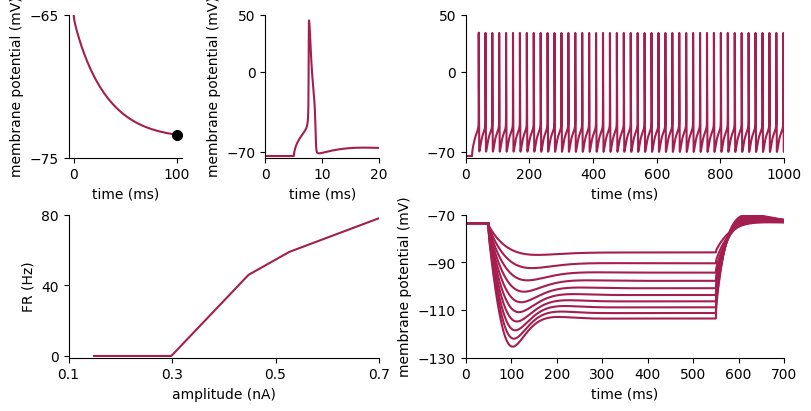

In [11]:
fig, axes = plot_all_experiments()
plt.show()
fig.savefig(figpth / 'l23_experiments.png', dpi=300)
fig.savefig(figpth / 'l23_experiments.pdf', dpi=300)
fig.savefig(figpth / 'l23_experiments.svg', dpi=300)

plt.close('all')

### Comparison to Allen data

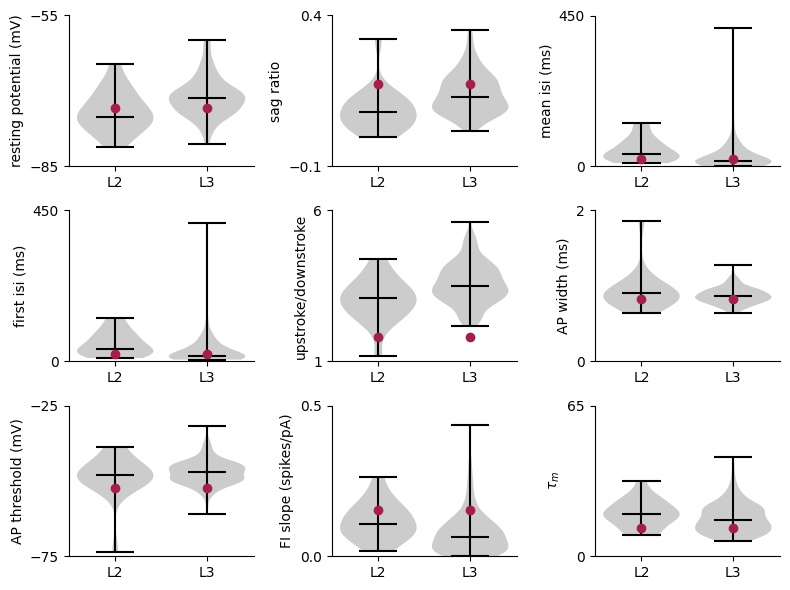

In [12]:
measures = ['RMP', 'sag', 'mean_isi', 'first_isi', 'upstroke_downstroke', 'ap_width', 'ap_threshold', 'FR_slope', 'tau']
label = ['resting potential (mV)', 'sag ratio', 'mean isi (ms)', 'first isi (ms)', 'upstroke/downstroke', 'AP width (ms)', 'AP threshold (mV)', 'FI slope (spikes/pA)', r'$\tau_{m}$']
ylims = [(-85, -55), (-0.1, 0.4), (0, 450), (0, 450), (1, 6), (0, 2), (-75, -25), (0, 0.5), (0, 65)]
fig, ax = plt.subplots(3, 3, figsize=(8, 6))
cm_neurons = get_cmap_neurons()

ax = ax.ravel()
for i, m in enumerate(measures):

    data = [l2_allen[m].dropna(), l3_allen[m].dropna()]
    v = ax[i].violinplot(data, positions=[1.2, 1.8], vert=True, showmeans=False,
                         showmedians=True)

    ax[i].plot(1.2, ephys_measures[m], 'o', color=cm_neurons[1], markersize=6)
    ax[i].plot(1.8, ephys_measures[m], 'o', color=cm_neurons[1], markersize=6)
    ax[i].set_ylabel(label[i])
    ax[i].set_xticks([1.2, 1.8], labels=['L2', 'L3'])
    ax[i].set_ylim(ylims[i])
    ax[i].set_yticks(ylims[i])
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)

    for pc in v['bodies']:
        pc.set_facecolor('black')
        pc.set_alpha(.2)
    v['cbars'].set_color('black')
    v['cmaxes'].set_color('black')
    v['cmins'].set_color('black')
    v['cmedians'].set_color('black')

fig.tight_layout()
fig.savefig(figpth / 'l23_cell_vs_allen.png')
fig.savefig(figpth / 'l23_cell_vs_allen.svg')
fig.savefig(figpth / 'l23_cell_vs_allen.pdf')

## Fig. 5 — calcium spikes

Dendritic calcium spikes evoked by tuft stimulation vs. no calcium spikes when injecting current into the soma (reproduces Gidon et al., 2020)

Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.


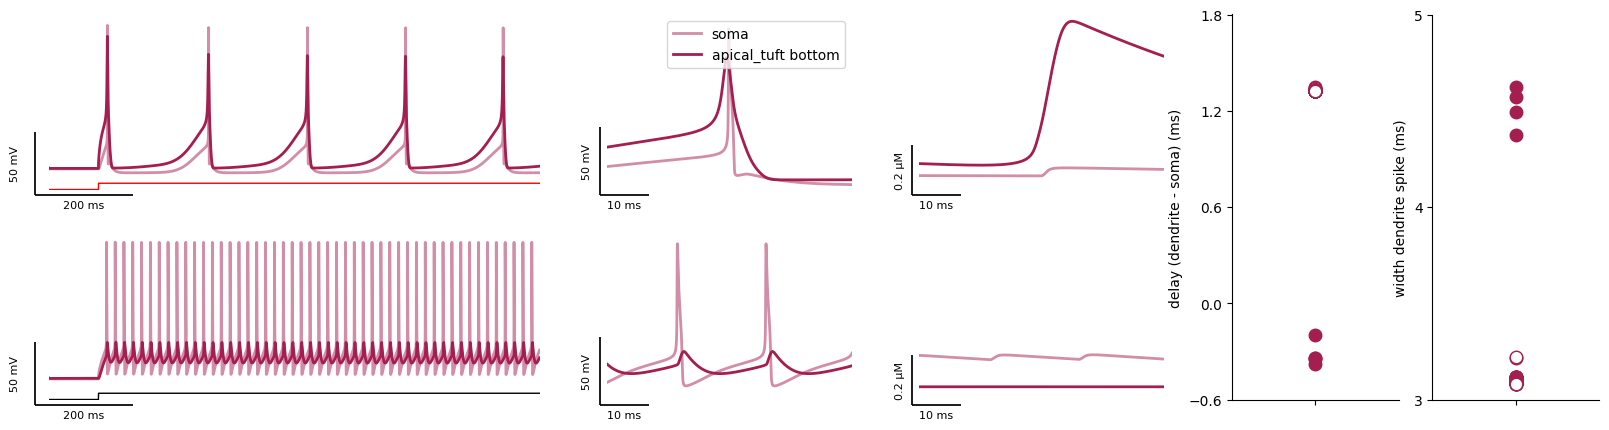

In [13]:
# figure
fig = plt.figure(figsize=(20, 5))
gs = GridSpec(2, 4, figure=fig, width_ratios=[1, 0.5, 0.5, 0.75])
gs_small = gridspec.GridSpecFromSubplotSpec(1, 2, subplot_spec=gs[0:2, 3])
ax = [None] * 8

# load l2pyr cell object
l2pyr = get_l2pyr()

# Ca spike: stimulus to dendrite
stim = h.IClamp(l2pyr._nrn_sections['apical_tuft'](0.1))
stim.delay = 100
stim.dur = 1000
stim.amp = .5
t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)
clamp_current = h.Vector().record(stim._ref_i)

dend_voltg = h.Vector().record(l2pyr._nrn_sections['apical_tuft'](0.1)._ref_v)

soma_ca = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_cai)

dend_ca = h.Vector().record(l2pyr._nrn_sections['apical_tuft'](0.1)._ref_cai)

h.celsius = 37
h.finitialize()
h.continuerun(1000 * ms)

t_np = t.as_numpy()
v_np = soma_voltg.as_numpy()
d_np = dend_voltg.as_numpy()
dend_peaks = find_peaks(d_np, height=-10, width=2, prominence=10)
soma_peaks = find_peaks(v_np, height=0, width=0.1)

# 1s stimulation
ax[0] = fig.add_subplot(gs[0, 0])
ax[0].plot(t, soma_voltg, color=cm_neurons[1], alpha=0.5, linewidth=2)
ax[0].plot(t, dend_voltg, color=cm_neurons[1], linewidth=2)
ax[0].plot(t, clamp_current * 10 - 90, color='r', linewidth=1)
ax[0].set_xlim([0, 1000])
ax[0].set_ylim([-90, 50])

# zoom in membrane potential
ax[1] = fig.add_subplot(gs[0, 1])
ax[1].plot(t, soma_voltg, label='soma', color=cm_neurons[1], alpha=0.5, linewidth=2)
ax[1].plot(t, dend_voltg, label='apical_tuft bottom', color=cm_neurons[1], linewidth=2)
ax[1].set_xlim([300, 350])
ax[1].legend()
ax[1].set_ylim([-80, 50])

# zoom in calcium
ax[2] = fig.add_subplot(gs[0, 2])
ax[2].plot(t, soma_ca, color=cm_neurons[1], alpha=0.5, linewidth=2)
ax[2].plot(t, dend_ca, color=cm_neurons[1], linewidth=2)
ax[2].set_xlim([300, 350])
ax[2].set_ylim([0, 0.0007])

# collect delay between Ca spike and action potential
delay = (dend_peaks[0] - soma_peaks[0]) * h.dt
widths = dend_peaks[1]['widths'] * h.dt

ax[3] = fig.add_subplot(gs_small[0, 0])
ax[3].plot(np.ones(len(delay)), delay, 'o', markeredgecolor=cm_neurons[1], label='delay bAP (ms)', color=cm_neurons[1], markersize=9)
ax[3].set_ylabel('delay (dendrite - soma) (ms)')
ax[3].set_xlim([0.75, 1.25])
ax[4] = fig.add_subplot(gs_small[0, 1])
ax[4].set_xlim([0.75, 1.25])
ax[4].plot(np.ones(len(widths)), widths, 'o', markeredgecolor=cm_neurons[1], label='width bAP (ms)', color=cm_neurons[1], markersize=9)
ax[4].set_ylabel('width dendrite spike (ms)')

del l2pyr
h('forall delete_section()')

# soma stimulation: backprop. AP
l2pyr = get_l2pyr()

stim = h.IClamp(l2pyr._nrn_sections['soma'](0.5))
stim.delay = 100
stim.dur = 1000
stim.amp = .5
t = h.Vector().record(h._ref_t)
soma_voltg = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_v)
clamp_current = h.Vector().record(stim._ref_i)

dend_voltg = h.Vector().record(l2pyr._nrn_sections['apical_tuft'](0.1)._ref_v)

soma_ca = h.Vector().record(l2pyr._nrn_sections['soma'](0.5)._ref_cai)

dend_ca = h.Vector().record(l2pyr._nrn_sections['apical_tuft'](0.1)._ref_cai)

h.celsius = 37
h.finitialize()
h.continuerun(1000 * ms)

t_np = t.as_numpy()
v_np = soma_voltg.as_numpy()
d_np = dend_voltg.as_numpy()
dend_peaks = find_peaks(d_np, width=0.5, height=-60)
soma_peaks = find_peaks(v_np, height=0, width=0.1)

# 1s simulation
ax[5] = fig.add_subplot(gs[1, 0])
ax[5].plot(t, soma_voltg, color=cm_neurons[1], alpha=0.5, linewidth=2)
ax[5].plot(t, dend_voltg, color=cm_neurons[1], linewidth=2)
ax[5].plot(t, clamp_current * 10 - 90, color='k', linewidth=1)
ax[5].set_xlim([0, 1000])
ax[5].set_ylim([-90, 50])

# zoom in on membrane potential
ax[6] = fig.add_subplot(gs[1, 1])
ax[6].plot(t, soma_voltg, label='soma', color=cm_neurons[1], alpha=0.5, linewidth=2)
ax[6].plot(t, dend_voltg, label='apical_tuft bottom', color=cm_neurons[1], linewidth=2)
ax[6].set_xlim([300, 350])
ax[6].set_ylim([-80, 50])

# zoom in on calcium
ax[7] = fig.add_subplot(gs[1, 2])
ax[7].plot(t, soma_ca, color=cm_neurons[1], alpha=0.5, linewidth=2)
ax[7].plot(t, dend_ca, color=cm_neurons[1], linewidth=2)
ax[7].set_xlim([300, 350])
ax[7].set_ylim([0, 0.0007])

# collect delay and width


delay = (dend_peaks[0] - soma_peaks[0]) * h.dt
widths = dend_peaks[1]['widths'] * h.dt

ax[3].plot(np.ones(len(delay)), delay, 'o', label='delay bAP (ms)', color='w', markeredgecolor=cm_neurons[1], markersize=9)
ax[3].set_ylabel('delay (dendrite - soma) (ms)')
ax[3].set_xlim([0.75, 1.25])
ax[4].set_xlim([0.75, 1.25])
ax[4].plot(np.ones(len(widths)), widths, 'o', label='width bAP (ms)', color='w', markeredgecolor=cm_neurons[1], markersize=9)
ax[4].set_ylabel('width dendrite spike (ms)')
ax[3].set_ylim([-0.6, 1.8])
ax[3].set_yticks(np.arange(-0.6, 1.81, 0.6))
ax[3].set_xticks([1])
ax[3].set_xticklabels([])
ax[4].set_xticks([1])
ax[4].set_xticklabels([])
ax[4].set_ylim([3, 5])
ax[4].set_yticks(np.arange(3, 5.1, 1))
# scale bars (replaces per-panel spine.set_bounds; anchored in axes fraction so
# they align across panels). x = time (ms); y = mV (traces) or mM ([Ca]).
for i in [0, 5]:      # full 1 s traces
    add_scalebar(ax[i], x_len=200, y_len=50, x_label='200 ms', y_label='50 mV')
for i in [1, 6]:      # membrane-potential zoom
    add_scalebar(ax[i], x_len=10, y_len=50, x_label='10 ms', y_label='50 mV')
for i in [2, 7]:      # calcium zoom
    add_scalebar(ax[i], x_len=10, y_len=0.0002, x_label='10 ms', y_label='0.2 µM')

for i in [3, 4]:      # delay / width scatter — keep ticked axes, just despine
    ax[i].spines['top'].set_visible(False)
    ax[i].spines['right'].set_visible(False)

fig.savefig(figpth / 'ca_spikes.png', dpi=300)
fig.savefig(figpth / 'ca_spikes.pdf', dpi=300)
fig.savefig(figpth / 'ca_spikes.svg', dpi=300)

## Supp. Fig. 2d–e — signal attenuation

Reproduces Gidon et al. 2020 and Gooch et al., 2022

In [14]:
# helper function
def plot_attenuation(model, ref_sect, section_names, use_epsp, cols_dist):

    fig, ax = plt.subplots(1, 5, figsize=(17, 2.5), constrained_layout=True)

    # hyperpolarization attenuation
    hyperpol_atten, elec_sep, _, ax[0] = attenuation_from_section(model=model, ref_sect=ref_sect, section_names=section_names, amp=-2, stim_dur=1000, ax=ax[0], cols_dist=cols_dist, epsp=False)
    popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(hyperpol_atten), p0=[100, hyperpol_atten[0]])
    lambda_hyperpol = popt[0]

    ax[1].plot(elec_sep, hyperpol_atten, 'o', color='w', markeredgecolor='k', markersize=7)
    ax[1].set_xlim(np.floor(elec_sep[0]), np.round(elec_sep[-1] + 100, -2))
    ax[1].set_xticks(np.linspace(0, np.round(elec_sep[-1] + 100, -2), 3))
    ax[1].set_xlabel(rf'distance from {ref_sect} ($\mu m$)')
    ax[1].set_ylabel('attenuation (%)')
    ax[1].set_ylim(0, 101)
    ax[1].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')
    ax[1].text(200, 70, f'{lambda_hyperpol:.2f}')  # Gidon 2020 475

    # spike attenuation
    model = get_l2pyr()

    spike_amp, _, upstroke, ax[2] = attenuation_from_section(model=model, ref_sect=ref_sect, section_names=section_names, amp=2, stim_dur=5, ax=ax[2], cols_dist=cols_dist, epsp=use_epsp)

    ax[3].plot(elec_sep, spike_amp, 'o', color='w', markeredgecolor='k', markersize=7)
    ax[3].set_xlim(np.floor(elec_sep[0]), np.round(elec_sep[-1] + 100, -2))
    ax[3].set_xticks(np.linspace(0, np.round(elec_sep[-1] + 100, -2), 3))
    popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(spike_amp), p0=[100, spike_amp[0]])
    lambda_spike_amp = popt[0]
    ax[3].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')
    ax[3].text(100, spike_amp.max(), f'{lambda_spike_amp:.2f}')  # Gidon 2020, 290

    ax[3].set_xlabel(rf'distance from {ref_sect} ($\mu m$)')
    ax[3].set_ylabel('attenuation (%)')

    ax[2].set_xlim([0, 60])
    ax[3].set_yticks(np.arange(0, 101, 25))

    ax[4].plot(elec_sep, upstroke, 'o', color='w', markeredgecolor='k', markersize=7)
    ax[4].set_xlim(np.floor(elec_sep[0]), np.round(elec_sep[-1] + 100, -2))
    ax[4].set_xticks(np.linspace(0, np.round(elec_sep[-1] + 100, -2), 3))
    popt, pcov = curve_fit(exp_decay, np.array(elec_sep), np.array(upstroke), p0=[100, upstroke[0]])
    ax[4].plot(elec_sep, exp_decay(np.array(elec_sep), *popt), color='k')
    lambda_upstroke = popt[0]
    ax[4].set_ylabel('bAP upstroke (mV/ms)')
    ax[4].text(100, upstroke.max(), f'{lambda_upstroke:.2f}')

    for a in ax:
        a.spines['top'].set_visible(False)
        a.spines['right'].set_visible(False)

    return fig

### Attenuation soma to dendrite (no EPSP)

Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
ref section: soma, recording from section: apical_trunk
ref section: soma, recording from section: apical_1
ref section: soma, recording from section: apical_tuft
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
ref section: soma, recording from section: apical_trunk
ref section: soma, recording from section: apical_1
ref section: soma, recording from section: apical_tuft


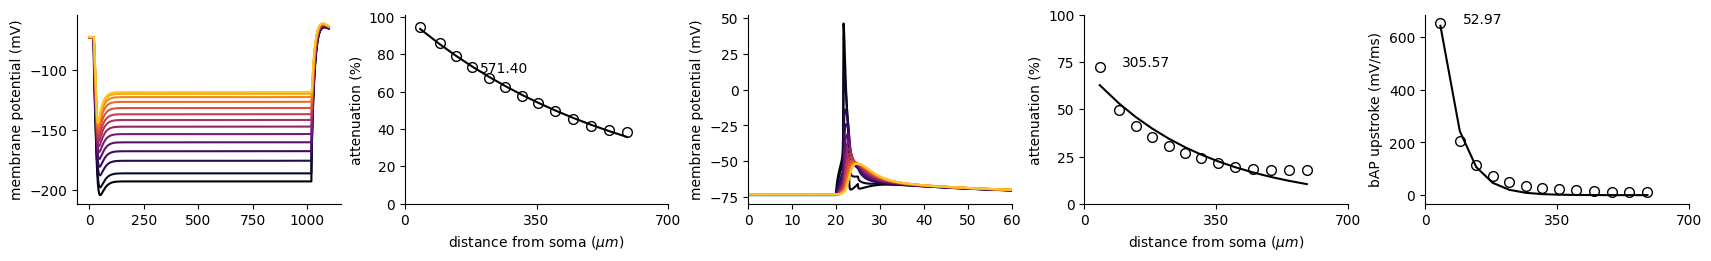

In [15]:
model = get_l2pyr()
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
ref_sect = 'soma'

fig = plot_attenuation(model=model, section_names=section_names, ref_sect=ref_sect, use_epsp=False, cols_dist=cols_dist)

fig.savefig(figpth / 'summary_attenuation_soma_dend.png', dpi=300)
fig.savefig(figpth / 'summary_attenuation_soma_dend.pdf', dpi=300)

### Attenuation tuft to soma (epsp input)

Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
ref section: apical_tuft, recording from section: apical_tuft
ref section: apical_tuft, recording from section: apical_1
ref section: apical_tuft, recording from section: apical_trunk
ref section: apical_tuft, recording from section: soma
Mechanisms already loaded from path: /Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/mod.  Aborting.
ref section: apical_tuft, recording from section: apical_tuft
ref section: apical_tuft, recording from section: apical_1
ref section: apical_tuft, recording from section: apical_trunk
ref section: apical_tuft, recording from section: soma


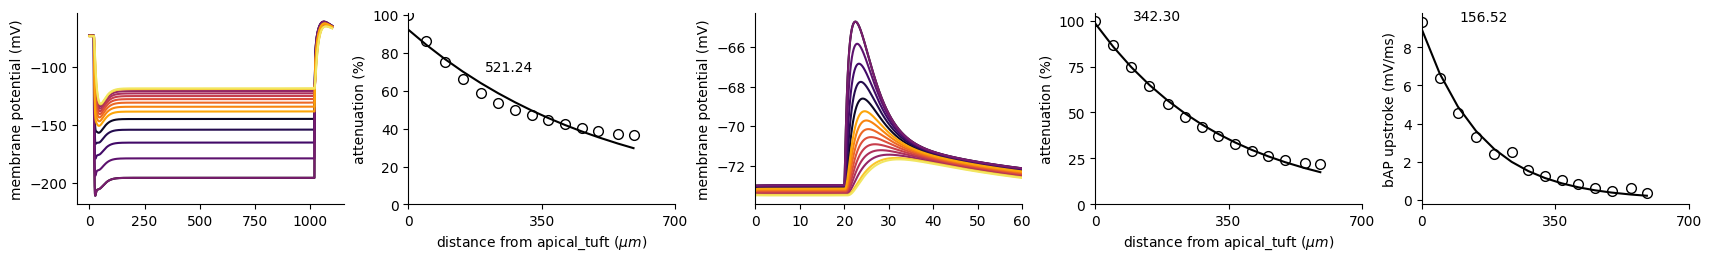

In [16]:
model = get_l2pyr()
section_names = ['soma', 'apical_trunk', 'apical_1', 'apical_tuft']
ref_sect = 'apical_tuft'

fig = plot_attenuation(model=model, section_names=section_names, ref_sect=ref_sect, use_epsp=True, cols_dist=cols_dist)

fig.savefig(figpth / 'summary_attenuation_dend_soma.png', dpi=300)
fig.savefig(figpth / 'summary_attenuation_dend_soma.pdf', dpi=300)

## Supp. Fig. 2g Single-cell dipolar currents

Dipole moment produced by a single L2/3 pyramidal cell. Reproduces Murakami and Okada, 2006

/Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/network.py:613: UserWarning: Zero distance between cells of type 'L2_inhibitory' in the X dimension in the provided 'pos_dict'. 
This can happen if: 
- you are simulating a network with only a single cell of this cell type, e.g. using `mesh_shape=(1, 1)`.
- the positions of 'L2_inhibitory' in your 'pos_dict' are all the same in the X dimension. 
If this is not intentional, check your 'pos_dict'!
  warnings.warn(
/Users/katharinaduecker/miniconda3/envs/hnn-tuning/lib/python3.12/site-packages/hnn_core/network.py:613: UserWarning: Zero distance between cells of type 'L2_inhibitory' in the Y dimension in the provided 'pos_dict'. 
This can happen if: 
- you are simulating a network with only a single cell of this cell type, e.g. using `mesh_shape=(1, 1)`.
- the positions of 'L2_inhibitory' in your 'pos_dict' are all the same in the Y dimension. 
If this is not intentional, check your 'pos_dict'!
  warni

Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...
Joblib will run 1 trial(s) in parallel by distributing trials over 1 jobs.
Building the NEURON model
[Done]
Trial 1: 0.03 ms...
Trial 1: 10.0 ms...
Trial 1: 20.0 ms...
Trial 1: 30.0 ms...
Trial 1: 40.0 ms...
Trial 1: 50.0 ms...
Trial 1: 60.0 ms...
Trial 1: 70.0 ms...


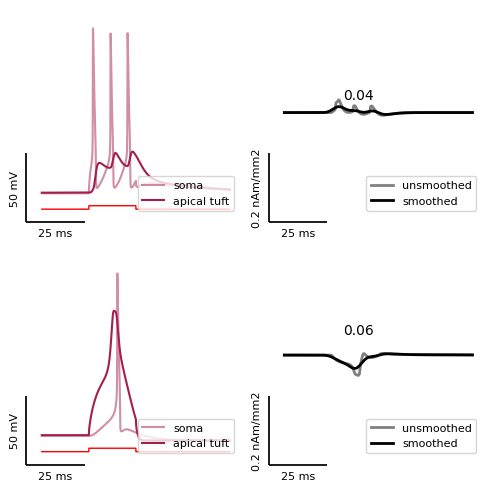

In [17]:
fig, axs = plt.subplots(2, 2, figsize=(5, 5), sharex=True)

gid = 1  # the single L2 pyramidal cell in the (1, 1) mesh

net, dpl, smooth_dpl = stim_dpl(duecker_ET_model(mesh_shape=(1, 1)), stim_cell='L2_pyramidal', ampl=2)
plot_dpl(net, dpl, smooth_dpl, axs[0, :], gid, cell_type='L2_pyramidal', dpl_ylim=(-0.3, 0.3), sb_dpl=0.2)

net, dpl, smooth_dpl = stim_dpl(duecker_ET_model(mesh_shape=(1, 1)), stim_cell='L2_pyramidal', stim_section='apical_tuft', ampl=0.6)
plot_dpl(net, dpl, smooth_dpl, axs[1, :], gid, cell_type='L2_pyramidal', dpl_ylim=(-0.3, 0.3), sb_dpl=0.2)

fig.tight_layout()

fig.savefig(figpth / 'l23_dipolar_currents.png', dpi=300, bbox_inches='tight')
fig.savefig(figpth / 'l23_dipolar_currents.pdf', dpi=300, bbox_inches='tight')
fig.savefig(figpth / 'l23_dipolar_currents.svg', dpi=300, bbox_inches='tight')